# 03. Torneio de 22 modelos independentes

**Pergunta:** qual tipo de modelo lida melhor com estas contagens de palavras?

**Protocolo.** Os mesmos 5 folds para todos (`StratifiedGroupKFold`, cópias idênticas sempre do mesmo lado).
Rodada 1: os 22 modelos, 1 × 5 folds. Rodada 2: os 5 melhores em 3 × 5 folds, com teste t corrigido
(Nadeau-Bengio) + Holm e o teste bayesiano correlacionado.

Os resultados do experimento 01 são reaproveitados (`experimentos/01_benchmark`); se o arquivo não existir,
o torneio roda do zero (cerca de 11 min) e retoma de onde parou se cair.

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/felipe44776-eseg/filtro-spam-stacking-enron/blob/main/notebooks/03_modelos_independentes.ipynb)

**No Google Colab:** rode tudo (*Ambiente de execução → Executar tudo*). Na primeira vez, a célula abaixo baixa o
projeto, instala os pacotes e **reinicia o ambiente**; quando o Colab reconectar, use *Executar tudo* de novo.
No computador, ela não faz nada (siga o [INSTALACAO.md](https://github.com/felipe44776-eseg/filtro-spam-stacking-enron/blob/main/INSTALACAO.md)).

In [1]:
# Google Colab: prepara o ambiente na primeira execução. No computador, esta célula não faz nada.
import os, subprocess, sys
if "google.colab" in sys.modules:
    PROJETO = "/content/filtro-spam-stacking-enron"
    if not os.path.isdir(PROJETO):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/felipe44776-eseg/filtro-spam-stacking-enron.git", PROJETO], check=True)
    os.chdir(PROJETO)
    sys.path.insert(0, PROJETO)
    MARCA = "/content/.spamfilter_instalado"
    if not os.path.exists(MARCA):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
        open(MARCA, "w").close()
        print("Pacotes instalados. O Colab vai reiniciar o ambiente: quando reconectar, use Executar tudo de novo.")
        os.kill(os.getpid(), 9)

In [2]:
import os
import shutil
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfTransformer

from spamfilter import caminhos, dados, estatistica, graficos, metricas, modelos, saidas
from spamfilter.dados import SEED

base = dados.carregar()
X, y, g = base.X, base.y, base.g
CATALOGO = modelos.torneio()


def avaliar(nome, semente):
    linhas = []
    for f, (tr, te) in enumerate(dados.divisoes(y, g, semente)):
        m = CATALOGO[nome](); t0 = time.time(); m.fit(X[tr], y[tr]); t1 = time.time()
        yh = m.predict(X[te]); s = modelos.nota(m, X[te])
        linhas.append(dict(modelo=nome, seed=semente, fold=f, **metricas.metricas_simples(y[te], yh, s),
                           fit_s=t1 - t0, n_tr=len(tr), n_te=len(te)))
    return linhas


def rodar(arquivo, nomes, sementes, historico=None):
    """Salva a cada modelo e retoma de onde parou. Começa do resultado histórico, se houver
    (com TORNEIO_DO_ZERO=1, ignora o histórico e treina tudo de novo)."""
    arquivo = caminhos.RESULTADOS / arquivo
    if not arquivo.exists() and historico is not None and historico.exists() and not os.environ.get("TORNEIO_DO_ZERO"):
        h = pd.read_csv(historico, sep=";", decimal=",").rename(columns={"fp_ham": "real_lixeira", "fn_spam": "spam_passou"})
        caminhos.RESULTADOS.mkdir(exist_ok=True); h.to_csv(arquivo, sep=";", decimal=",", index=False)
    feitos = pd.read_csv(arquivo, sep=";", decimal=",") if arquivo.exists() else pd.DataFrame(columns=["modelo", "seed"])
    for s in sementes:
        for nome in nomes:
            if ((feitos.modelo == nome) & (feitos.seed == s)).any():
                continue
            pd.DataFrame(avaliar(nome, s)).to_csv(arquivo, sep=";", decimal=",", index=False, mode="a", header=not arquivo.exists())
            print(f"semente {s} | {nome}", flush=True)
    return pd.read_csv(arquivo, sep=";", decimal=",")

## Rodada 1: os 22 modelos

                            mcc  mcc_dp  pr_auc  real_lixeira  spam_passou  treino_s         familia
Stacking (meta LR)        0.970   0.009   0.997           1.1          1.6     13.23      combinação
LinearSVC TF-IDF          0.963   0.004   0.996           1.6          1.4      0.06          linear
SVM RBF SVD300            0.962   0.014   0.996           1.8          1.1      1.56          kernel
SGD (huber) TF-IDF        0.962   0.007   0.993           1.7          1.3      0.02          linear
Reg. Logística TF-IDF     0.961   0.007   0.996           1.9          1.1      0.06          linear
Ridge TF-IDF              0.960   0.004   0.996           1.9          1.1      0.04          linear
MLP (rede neural)         0.960   0.014   0.994           1.3          2.6      1.88     rede neural
Votação (LR+CNB+RF+LGBM)  0.959   0.007   0.996           2.1          0.9      2.61      combinação
NBSVM                     0.957   0.007   0.992           1.9          1.6      0.05       

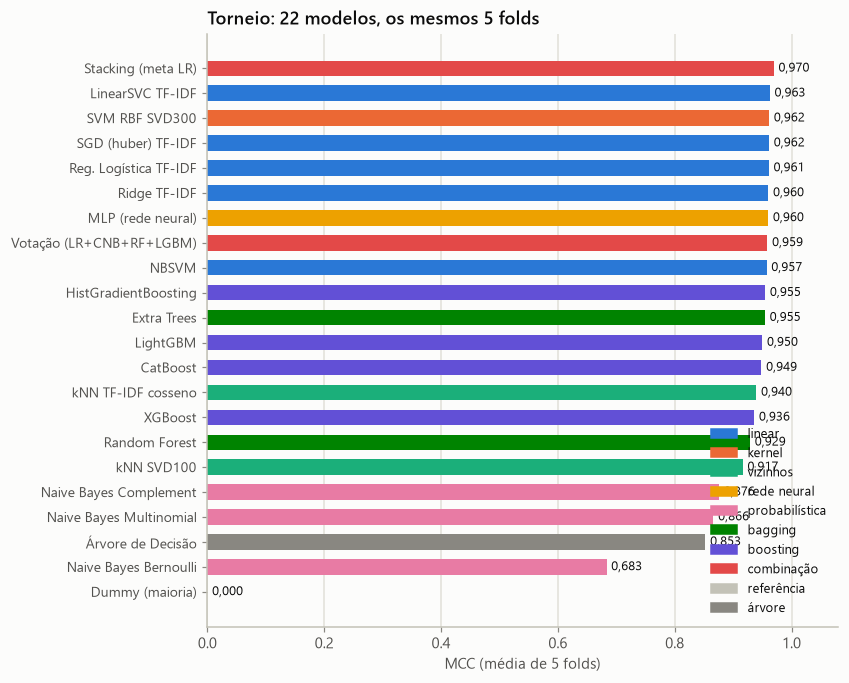

In [3]:
H = caminhos.EXPERIMENTOS / "01_benchmark"
R1 = rodar("03_torneio_rodada1.csv", list(CATALOGO), [SEED], H / "bench_rodada1.csv")
tab = (R1.groupby("modelo").agg(mcc=("mcc", "mean"), mcc_dp=("mcc", "std"), pr_auc=("pr_auc", "mean"),
                                real_lixeira=("real_lixeira", "mean"), spam_passou=("spam_passou", "mean"), treino_s=("fit_s", "mean"))
       .sort_values("mcc", ascending=False))
tab["familia"] = [modelos.FAMILIA_TORNEIO[n] for n in tab.index]
tab.index = [modelos.NOMES_TORNEIO.get(n, n) for n in tab.index]
mostra = tab.copy(); mostra[["real_lixeira", "spam_passou"]] *= 100
print(mostra.round({"mcc": 3, "mcc_dp": 3, "pr_auc": 3, "real_lixeira": 1, "spam_passou": 1, "treino_s": 2}).to_string())

fig, ax = plt.subplots(figsize=(7.4, 7))
t = tab.iloc[::-1]
ax.barh(range(len(t)), t.mcc.clip(lower=0), height=0.62, color=[graficos.FAMILIA_COR[f] for f in t.familia])
for i, v in enumerate(t.mcc):
    ax.text(max(v, 0) + 0.008, i, f"{v:.3f}".replace(".", ","), va="center", fontsize=8.5)
ax.set_yticks(range(len(t)), t.index, fontsize=9); ax.grid(axis="y", visible=False); ax.set_xlim(0, 1.08)
ax.set_xlabel("MCC (média de 5 folds)"); ax.set_title("Torneio: 22 modelos, os mesmos 5 folds")
from matplotlib.patches import Patch
fams = [f for f in graficos.FAMILIA_COR if f in set(t.familia)]
ax.legend(handles=[Patch(color=graficos.FAMILIA_COR[f], label=f) for f in fams], loc="lower right", fontsize=8.5)
graficos.mostrar(fig, "03_torneio")

## O detalhe que virou o jogo: TF-IDF com log
Contar "spam" 10 vezes não é 10 vezes mais evidência que contar 1 vez. O log (`sublinear_tf`) achata as
repetições, e os modelos que dependem de distância e de pesos lineares melhoram muito.

In [4]:
def mcc_cv(criar):
    return float(np.mean([metricas.mcc_np(y[te], criar().fit(X[tr], y[tr]).predict(X[te])) for tr, te in dados.divisoes(y, g, SEED)]))

lr = lambda tf: (lambda: make_pipeline(*tf, LogisticRegression(C=10, max_iter=3000, class_weight="balanced")))
knn = lambda tf: (lambda: make_pipeline(*tf, KNeighborsClassifier(5, metric="cosine")))
REPS = {"contagem crua": [], "TF-IDF": [TfidfTransformer()], "TF-IDF com log": [TfidfTransformer(sublinear_tf=True)]}
ACH = pd.DataFrame({rot: {"Reg. Logística": mcc_cv(lr(tf)), "kNN cosseno": mcc_cv(knn(tf))} for rot, tf in REPS.items()})
print(ACH.round(3).to_string())

                contagem crua  TF-IDF  TF-IDF com log
Reg. Logística          0.921   0.923           0.961
kNN cosseno             0.709   0.746           0.940


## Rodada 2: os 5 melhores em 3 × 5 folds

In [5]:
top = list(R1.groupby("modelo").mcc.mean().sort_values(ascending=False).index[:5])
R2 = rodar("03_torneio_rodada2.csv", top, [7, 2026], H / "bench_rodada2.csv")
RR = pd.concat([R1[R1.modelo.isin(top)], R2[R2.modelo.isin(top)]])
P = RR.pivot_table(index=["seed", "fold"], columns="modelo", values="mcc")
melhor = P.mean().idxmax()
C = estatistica.comparar(P, [(melhor, o) for o in P.columns.drop(melhor)], RR.n_tr.mean(), RR.n_te.mean(), runs=3)
print(f"melhor em 15 folds: {melhor} ({P[melhor].mean():.4f})")
print(C[["A", "B", "dif", "p", "p_holm", "P_A_melhor", "P_equivalentes", "P_B_melhor"]].round(4).to_string(index=False))

melhor em 15 folds: Stacking (meta LR) (0.9701)
                 A                     B    dif      p  p_holm  P_A_melhor  P_equivalentes  P_B_melhor
Stacking (meta LR) Reg. Logistica TF-IDF 0.0108 0.0087  0.0348      0.5869          0.4130      0.0000
Stacking (meta LR)    SGD (huber) TF-IDF 0.0094 0.0534  0.1603      0.4494          0.5503      0.0003
Stacking (meta LR)        SVM RBF SVD300 0.0099 0.0830  0.1660      0.4918          0.5071      0.0011
Stacking (meta LR)      LinearSVC TF-IDF 0.0088 0.0847  0.1660      0.4022          0.5971      0.0007


**Leitura.** Os modelos lineares sobre TF-IDF com log formam um pelotão (MCC ≈ 0,96); o boosting, que costuma
vencer em tabelas, fica atrás. O stacking simples (4 modelos) lidera, mas **não** se separa estatisticamente do
LinearSVC depois da correção de Holm: com 15 folds, diferenças abaixo de ~0,01 não são detectáveis.

In [6]:
saidas.gravar("03_torneio", {
    "torneio": [dict(modelo=n, **r) for n, r in tab.iterrows()],
    "achados": dict(tfidf_log=ACH.to_dict(), lr_mcc_antes=ACH.loc["Reg. Logística", "TF-IDF"], lr_mcc_depois=ACH.loc["Reg. Logística", "TF-IDF com log"],
                    knn_mcc_antes=ACH.loc["kNN cosseno", "TF-IDF"], knn_mcc_depois=ACH.loc["kNN cosseno", "TF-IDF com log"],
                    votacao_mcc=float(tab.loc["Votação (LR+CNB+RF+LGBM)", "mcc"]), lr_mcc=float(tab.loc["Reg. Logística TF-IDF", "mcc"])),
    "rodada2": dict(melhor=melhor, mcc_15_folds=P.mean().to_dict(), comparacoes=C),
}, fonte="scripts/03_modelos_independentes.py")
print("gravado: resultados/03_torneio.json")

gravado: resultados/03_torneio.json
